# TikTok: Claims Classification Data (Visualization Stage)

Case study from the Google Advanced Data Analytics Professional Certificate. Building on the Plan/Analyze stage, this notebook explores video engagement distributions and their relationship to claim status and author ban status, ahead of building an executive-facing story in Tableau and Python.

## Plan

### Outliers: how to identify and handle them



we can use the interquantile to identify the outliers or by using boxplot, or by simply using describe() and check for outliers.
If its a typo or it can ruin the models performance remove them, if not then keep them.

## Analyze

### Imports and data loading


In [1]:
# Import packages for data manipulation
import numpy as np
import pandas as pd

# Import packages for data visualization
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Load dataset into dataframe
data = pd.read_csv("tiktok_dataset.csv")

### Data exploration and cleaning


In [3]:
# Display and examine the first few rows of the dataframe
data.head()


,#,claim_status,video_id,video_duration_sec,video_transcription_text,verified_status,author_ban_status,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count
0,1,claim,7017666017,59,someone shared with me that drone deliveries a...,not verified,under review,343296.0,19425.0,241.0,1.0,0.0
1,2,claim,4014381136,32,someone shared with me that there are more mic...,not verified,active,140877.0,77355.0,19034.0,1161.0,684.0
2,3,claim,9859838091,31,someone shared with me that american industria...,not verified,active,902185.0,97690.0,2858.0,833.0,329.0
3,4,claim,1866847991,25,someone shared with me that the metro of st. p...,not verified,active,437506.0,239954.0,34812.0,1234.0,584.0
4,5,claim,7105231098,19,someone shared with me that the number of busi...,not verified,active,56167.0,34987.0,4110.0,547.0,152.0


In [4]:
# Get the size of the data
data.size


232584

In [5]:
# Get the shape of the data
data.shape


(19382, 12)

In [6]:
# Get basic information about the data
data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19382 entries, 0 to 19381
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   #                         19382 non-null  int64  
 1   claim_status              19084 non-null  object 
 2   video_id                  19382 non-null  int64  
 3   video_duration_sec        19382 non-null  int64  
 4   video_transcription_text  19084 non-null  object 
 5   verified_status           19382 non-null  object 
 6   author_ban_status         19382 non-null  object 
 7   video_view_count          19084 non-null  float64
 8   video_like_count          19084 non-null  float64
 9   video_share_count         19084 non-null  float64
 10  video_download_count      19084 non-null  float64
 11  video_comment_count       19084 non-null  float64
dtypes: float64(5), int64(3), object(4)
memory usage: 1.8+ MB


In [7]:
# Generate a table of descriptive statistics
data.describe()


,#,video_id,video_duration_sec,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count
count,19382.000000,1.938200e+04,19382.000000,19084.000000,19084.000000,19084.000000,19084.000000,19084.000000
mean,9691.500000,5.627454e+09,32.421732,254708.558688,84304.636030,16735.248323,1049.429627,349.312146
std,5595.245794,2.536440e+09,16.229967,322893.280814,133420.546814,32036.174350,2004.299894,799.638865
min,1.000000,1.234959e+09,5.000000,20.000000,0.000000,0.000000,0.000000,0.000000
25%,4846.250000,3.430417e+09,18.000000,4942.500000,810.750000,115.000000,7.000000,1.000000
50%,9691.500000,5.618664e+09,32.000000,9954.500000,3403.500000,717.000000,46.000000,9.000000
75%,14536.750000,7.843960e+09,47.000000,504327.000000,125020.000000,18222.000000,1156.250000,292.000000
max,19382.000000,9.999873e+09,60.000000,999817.000000,657830.000000,256130.000000,14994.000000,9599.000000


### Select visualization types

Which chart types make the most sense for EDA on this dataset?

Bar chart, box plot, histogram, and scatter plot.

## Construct


### Build visualizations


**video_duration_sec**


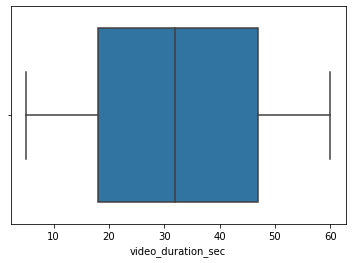

In [8]:
# Create a boxplot to visualize distribution of `video_duration_sec`
sns.boxplot(data["video_duration_sec"])



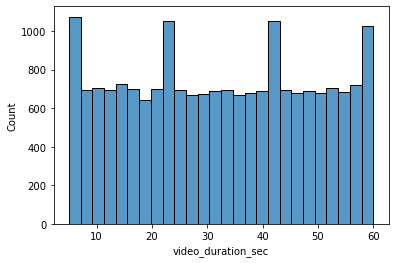

In [9]:
# Create a histogram
sns.histplot(data["video_duration_sec"])


**video_view_count**


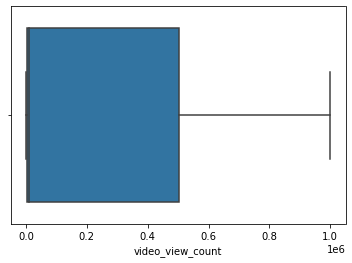

In [10]:
# Create a boxplot to visualize distribution of `video_view_count`
sns.boxplot(data["video_view_count"])



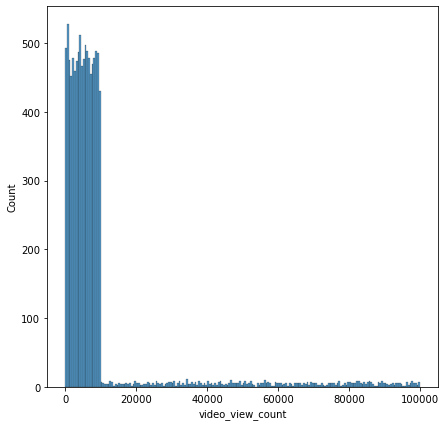

In [11]:
# Create a histogram
plt.figure(figsize=(7,7))
sns.histplot(data["video_view_count"], binrange=(0, 100000))


**video_like_count**


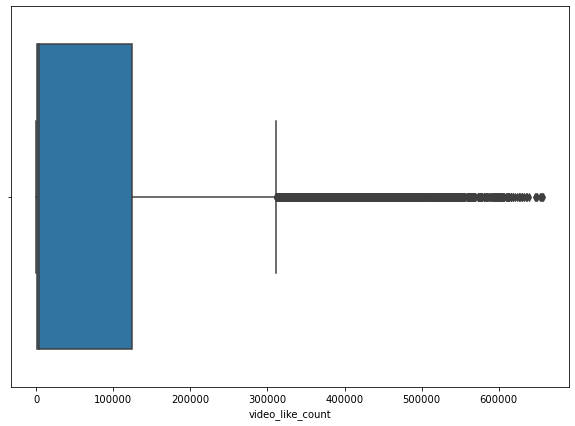

In [12]:
# Create a boxplot to visualize distribution of `video_like_count`
plt.figure(figsize=(10,7))
sns.boxplot(data["video_like_count"])



Text(0.5, 1.0, 'Video Like Count')

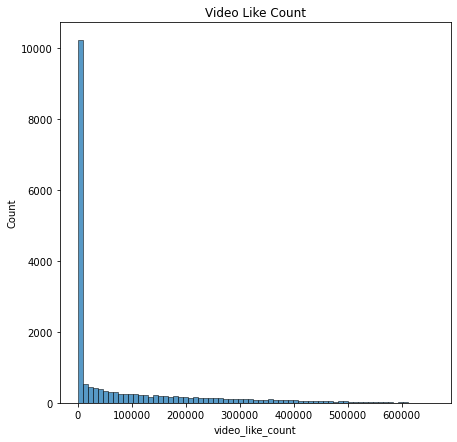

In [13]:
# Create a histogram
plt.figure(figsize=(7,7))
sns.histplot(data["video_like_count"])
plt.title("Video Like Count")


**video_comment_count**


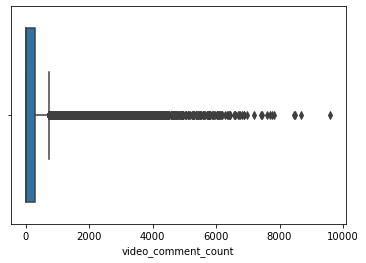

In [14]:
# Create a boxplot to visualize distribution of `video_comment_count`
sns.boxplot(data["video_comment_count"])



Text(0.5, 1.0, 'Video Comment Count')

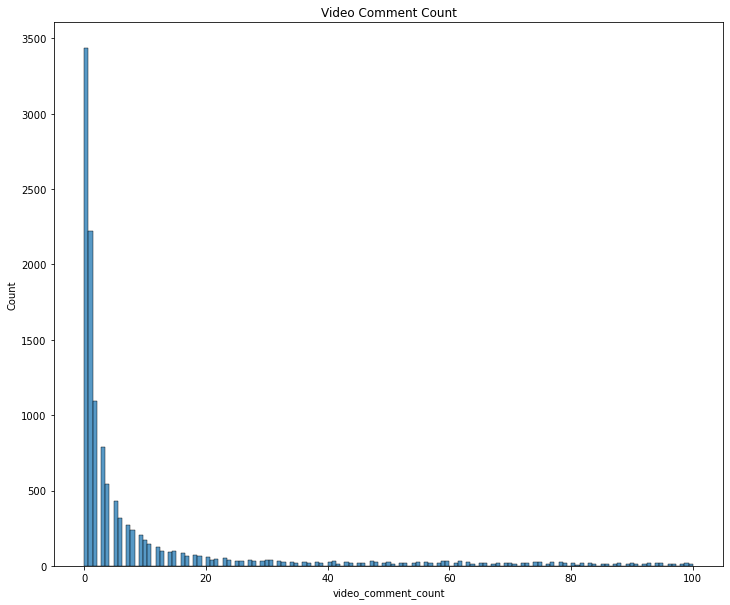

In [15]:
# Create a histogram
plt.figure(figsize=(12,10))
sns.histplot(data["video_comment_count"],binrange=(0, 100))
plt.title("Video Comment Count")


**video_share_count**


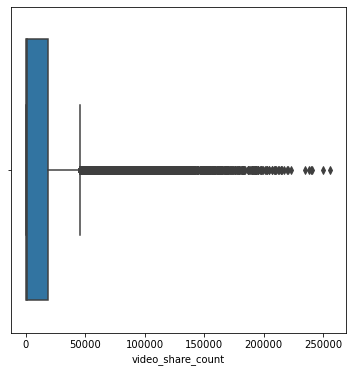

In [16]:
# Create a boxplot to visualize distribution of `video_share_count`
plt.figure(figsize=(6,6))
sns.boxplot(data["video_share_count"])


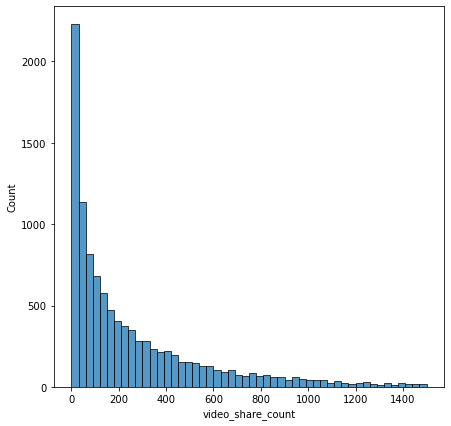

In [17]:
# Create a histogram
plt.figure(figsize=(7,7))
sns.histplot(data["video_share_count"],binrange=(0, 1500))


**video_download_count**


Text(0.5, 1.0, 'Video Downloads Count')

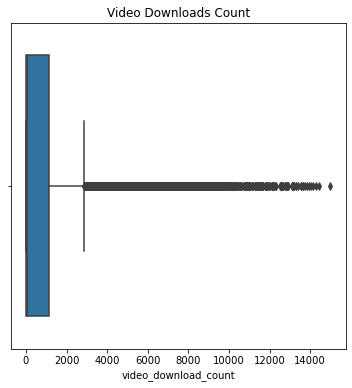

In [18]:
# Create a boxplot to visualize distribution of `video_download_count`
plt.figure(figsize=(6,6))
sns.boxplot(data["video_download_count"])
plt.title("Video Downloads Count")


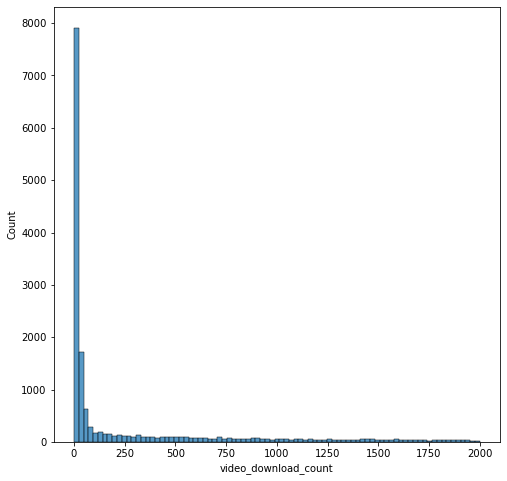

In [19]:
# Create a histogram
plt.figure(figsize=(8,8))
sns.histplot(data["video_download_count"], binrange=(0,2000))


**Claim status by verification status**


Text(0.5, 1.0, 'Count of Claim Status by Verification Status')

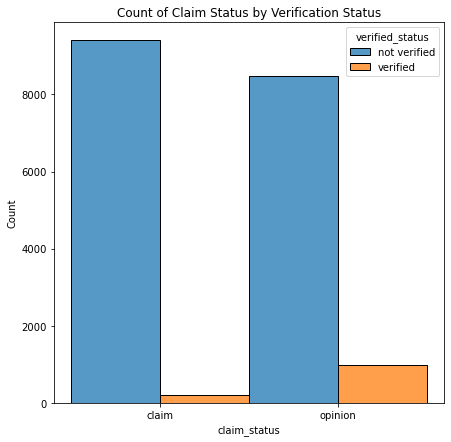

In [20]:
# Create a histogram
plt.figure(figsize= (7,7))
sns.histplot(x= data["claim_status"],hue=data["verified_status"], multiple="dodge")
plt.title("Count of Claim Status by Verification Status")


**Claim status by author ban status**


Text(0.5, 1.0, 'Claim Status Count by Author Ban Status')

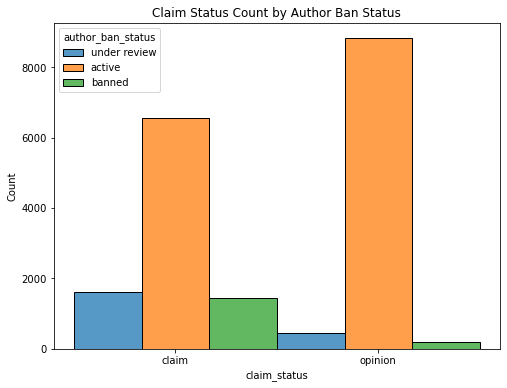

In [21]:
# Create a histogram
plt.figure(figsize=(8,6))
sns.histplot(x= data["claim_status"], hue=data["author_ban_status"], multiple="dodge")
plt.title("Claim Status Count by Author Ban Status")


**Median view counts by ban status**


Text(0.5, 1.0, 'Median of Author Ban Status Views Count')

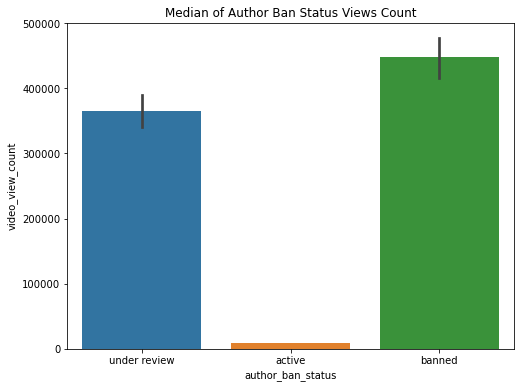

In [22]:
# Create a bar plot
plt.figure(figsize=(8,6))
sns.barplot(x = data["author_ban_status"], y=data["video_view_count"], estimator=np.median )
plt.title("Median of Author Ban Status Views Count")

In [23]:
# Calculate the median view count for claim status.
claim_views = data.groupby("claim_status")["video_view_count"].median()
claim_views

claim_status
claim      501555.0
opinion      4953.0
Name: video_view_count, dtype: float64

**Total views by claim status**


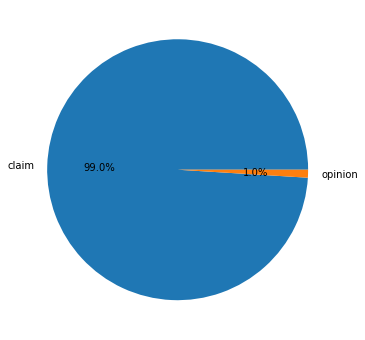

In [24]:
# Create a pie graph
plt.figure(figsize=(6,6))
plt.pie(claim_views, labels=claim_views.index, autopct="%1.1f%%");


### Determine outliers

Write a loop over each count variable's column: calculate its IQR and median, set the outlier threshold at median + 1.5*IQR (rather than the usual 3rd-quartile-based threshold, since these variables are heavily right-skewed), and count how many rows exceed it.

In [25]:
def outliers(df,column):
    q1 = data[column].quantile(0.25)
    q3 = data[column].quantile(0.75)
    iqr = q3 - q1 
    upper = df[column].median() + 1.5 * iqr
    outliers = df[df[column] > upper]
    return len(outliers)
columns = ["video_view_count", "video_like_count", "video_share_count", "video_download_count", "video_comment_count"]
for column in columns:
     print(f"Number of Outliers, ", column ,": ", outliers(data,column))


Number of Outliers,  video_view_count :  2343
Number of Outliers,  video_like_count :  3468
Number of Outliers,  video_share_count :  3732
Number of Outliers,  video_download_count :  3733
Number of Outliers,  video_comment_count :  3882


### Scatterplots


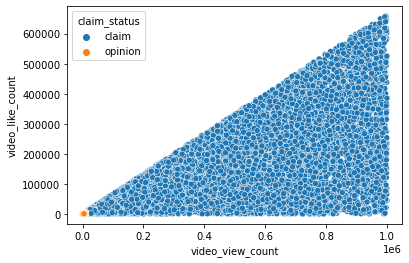

In [31]:
# Create a scatterplot of `video_view_count` versus `video_like_count` according to 'claim_status'
sns.scatterplot(x=data["video_view_count"], y=data["video_like_count"], hue=data["claim_status"])


Text(0.5, 1.0, 'Scatter plot of Opinions (views/Likes Count)')

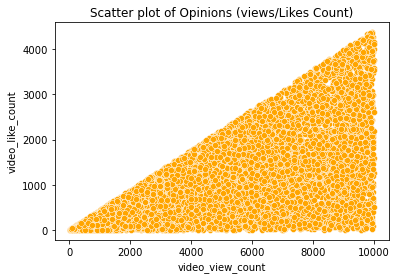

In [37]:
# Create a scatterplot of ``video_view_count` versus `video_like_count` for opinions only
mask = data[data["claim_status"] == "opinion"]
sns.scatterplot(x=mask["video_view_count"], y=mask["video_like_count"], color = "orange")
plt.title("Scatter plot of Opinions (views/Likes Count)")


## Execute


### Results and evaluation

What did the visualizations reveal about the dataset, and what further questions did they raise?


### Conclusion




EDA is important because you can know the relations between columns and know the datatypes


Visualizations helped me understand distribution and outliers at a glance patterns that would be hard to spot just scrolling through raw numbers.


You’ve now completed a professional data visualization according to a business need. Well done! Be sure to save your work as a reference for later work in Tableau.